# Do Stable Features Transfer?
## Source-Only Feature Selection for Cross-Dataset Phishing URL Detection

**Project category:** General Machine Learning (application project)

**Study question.** If a lexical URL classifier is trained on one public phishing dataset and deployed on a
different one *without target data for fitting, feature selection or threshold calibration*, how much does it degrade, and does choosing features by
the **stability** of their importance across held-out domains (STABLE_PI) transfer better than choosing them by
**mean** importance (MEAN_PI) or using **all** 37 features (ALL)?

| | |
|---|---|
| **Sources** | A = EBBU-2017 · B = HISPAR–Phishstats (HP) |
| **Classifiers** | Random Forest · LightGBM (fixed hyper-parameters) |
| **Feature conditions** | ALL (37) · MEAN_PI · STABLE_PI (budget *k* chosen by nested CV) |
| **Evaluation cells** | A→A · A→B · B→B · B→A (same model & threshold for both cells of a source) |
| **Seeds** | 17 · 29 · 43 |

| RQ | Question |
|---|---|
| RQ1 | How far do RF and LightGBM drop on another source with disjoint domains? |
| RQ2 | Does STABLE_PI change transfer F1 vs MEAN_PI at the same *k*, and vs ALL? |
| RQ3 | Does a smaller feature set measurably reduce extraction/inference cost? |
| RQ4 | Which features do the models rely on, and how do attributions shift source → target? |
| RQ5 | *(exploratory, FIT/VAL only)* Why does transfer fail where it does? Baselines, HTTPS ablation, EDA, error analysis. |

### How to read this notebook
* All logic lives in the tested package `src/phishresearch/`. Every cell below performs **one** step by
  calling one package function, then shows its output.
* This notebook **only loads saved artefacts**. It verifies the freeze before loading research results and refuses
  missing/partial outputs. It never starts acquisition, training, evaluation, or analysis during Run All.
* Individual TEST labels are not loaded here. Data checks use label-free metadata and saved aggregate diagnostics.
* Numbers are never typed by hand; the final section composes the answers from the artefacts.

## Project positioning · two primary papers

The assignment permits **two primary papers** and retains its **3–5-year recency rule**.
Our primary pair is Sánchez-Paniagua et al. (2022,
[login-URL representativeness and classifiers](https://doi.org/10.1109/ACCESS.2022.3168681)) and Rashid et al. (2024,
[transfer/UDA](https://doi.org/10.1016/j.comnet.2024.110398)). Both fall within the five-year
window as of 16 November 2026; the 2022 paper is outside the preferred three-year window.
The 2022 study evaluates RF/LightGBM, but its best overall pipeline uses **TF-IDF/n-grams + LR**;
the 2024 paper studies **UDA**. This project evaluates RF/LightGBM rather than reproducing them.
Historical EBBU and algorithm provenance remains in the repository; the active bibliography
uses recent studies. This is an application and empirical benchmark (General Machine Learning).

**Gap tested:** with no target data for fitting, feature selection or threshold calibration,
does source-domain stability improve transfer over mean importance **at matched k**, and is
any compression worth its detection-cost trade-off? Target identities still inform the
shared-domain purge, so acquisition is not target-blind.

**Contributions:** an auditable domain-disjoint protocol; a controlled selector comparison
in both directions; and empirical transfer–cost evidence including negative results against ALL.
Neither cross-dataset testing nor feature stability is claimed as a new idea. Existing adjacent
work remains acknowledged; two primary papers do not prove global novelty. SHAP is secondary
and retains the validation warning displayed later.

This wording was clarified **after evaluation** without changing the frozen experiment.
See `docs/project_positioning.md` for evidence and submission checks. Paper recency does not
make the frozen EBBU/HP datasets contemporary. Complete full-text review is still pending for R2.

## Part 0 · Environment

### Step 0.0: Check that the notebook runs in the project environment

The frozen run used the exact package versions in `requirements.lock` (Python 3.10). A different kernel (e.g. Anaconda) may lack packages such as `shap` or produce different numbers, so we stop early with a clear message. In VS Code choose the kernel **Python 3.10 (phishresearch)** (top-right *Select Kernel*).

In [1]:
import sys, importlib, re, warnings
from pathlib import Path
_root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
              if (p / "requirements.lock").is_file() and (p / "configs/protocol.yaml").is_file()), None)
if _root is None:
    raise RuntimeError("Project root not found. Start Jupyter from this repository or its notebooks directory.")
_lock = dict(re.findall(r"^([A-Za-z0-9_.-]+)==([^\s;]+)", (_root / "requirements.lock").read_text(encoding="utf-8"), re.M))
_need = {"numpy": "numpy", "pandas": "pandas", "scikit-learn": "sklearn", "lightgbm": "lightgbm", "shap": "shap",
         "pyarrow": "pyarrow", "matplotlib": "matplotlib", "joblib": "joblib", "idna": "idna",
         "PyYAML": "yaml", "psutil": "psutil", "scipy": "scipy"}
_rows, _bad = [], []
for dist, mod in _need.items():
    try:
        with warnings.catch_warnings():          # silences tqdm's IProgress notice raised by `import shap`
            warnings.simplefilter("ignore")
            have = importlib.import_module(mod).__version__
    except ImportError:
        have = "MISSING"
    ok = have == _lock.get(dist)
    _rows.append((dist, _lock.get(dist), have, "ok" if ok else "MISMATCH")); _bad += [] if ok else [dist]
print(f"kernel python : {sys.version.split()[0]}  ({sys.executable})")
for r in _rows: print(f"  {r[0]:13s} lock {r[1]:9s} kernel {r[2]:9s} {r[3]}")
if _bad or sys.version_info[:2] != (3, 10):
    raise RuntimeError(f"Wrong kernel/environment ({', '.join(_bad) or 'python version'}). Select the kernel "
                       "'Python 3.10 (phishresearch)' or run: python -m pip install -r requirements.lock")
print("environment matches requirements.lock")

kernel python : 3.10.0  (C:\Program Files\Python310\python.exe)
  numpy         lock 2.2.6     kernel 2.2.6     ok
  pandas        lock 2.3.1     kernel 2.3.1     ok
  scikit-learn  lock 1.7.2     kernel 1.7.2     ok
  lightgbm      lock 4.6.0     kernel 4.6.0     ok
  shap          lock 0.49.1    kernel 0.49.1    ok
  pyarrow       lock 21.0.0    kernel 21.0.0    ok
  matplotlib    lock 3.10.7    kernel 3.10.7    ok
  joblib        lock 1.5.3     kernel 1.5.3     ok
  idna          lock 3.20      kernel 3.20      ok
  PyYAML        lock 6.0.2     kernel 6.0.2     ok
  psutil        lock 7.0.0     kernel 7.0.0     ok
  scipy         lock 1.15.3    kernel 1.15.3    ok
environment matches requirements.lock


### Step 0.1: Locate the project and import the package

The notebook may be started from the repository root or from `notebooks/`; we normalise the working directory so all relative paths in the configs resolve.

In [2]:
import os, sys, json, copy, tempfile, warnings
from pathlib import Path

ROOT = _root
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd
from IPython.display import display, Markdown
import phishresearch
from phishresearch import nbviz as viz
from phishresearch.common import Paths, GateError, load_yaml, read_json, effective_threads, environment_info

plt = viz.setup_plots()
pd.set_option("display.precision", 4, "display.max_colwidth", 90, "display.width", 200)
print(f"phishresearch {phishresearch.__version__} | root: {ROOT}")

phishresearch 1.0.0 | root: D:\S2-AI\SEMESTER-1\Pemrograman Untuk Sains Data Dan Kecerdasan Artificial\UAS\PROJECT\ex


### Step 0.2: Load the frozen protocol and dataset registry

`protocol.yaml` holds every researcher decision (splits, k-candidates, hyper-parameters, bootstrap size); `datasets.yaml` pins each source to a Git commit and records the label-mapping evidence.

In [3]:
CFG = load_yaml("configs/protocol.yaml")
REGISTRY = load_yaml("configs/datasets.yaml")
P = Paths.from_config(CFG, ROOT)
from phishresearch.freeze import verify_freeze
FREEZE = verify_freeze(P.freeze, ROOT)
print("Frozen inputs verified:", FREEZE["freeze_hash"])

pd.Series({
    "protocol version": CFG["protocol_version"],
    "split seed / ratios": f"{CFG['splits']['seed']} / {CFG['splits']['ratios']}",
    "k candidates / q": f"{CFG['selection']['k_candidates']} / {CFG['selection']['q']}",
    "model seeds": CFG["models"]["seeds"],
    "RF": CFG["models"]["rf"], "LightGBM (main)": {k: CFG["models"]["lgbm"][k] for k in ("n_estimators", "learning_rate", "num_leaves")},
    "bootstrap replicates": CFG["statistics"]["bootstrap_replicates"],
    "source A commit": REGISTRY["sources"]["A"]["commit"][:12], "source B commit": REGISTRY["sources"]["B"]["commit"][:12],
}).to_frame("value")

Frozen inputs verified: 069912e332d788120e4ba358b1f8cd3dc5f0903d783249a87567ce00d6efc8da


,value
protocol version,1
split seed / ratios,"20261115 / {'FIT': 0.6, 'VAL': 0.2, 'TEST': 0.2}"
k candidates / q,"[8, 16, 24] / 12"
model seeds,"[17, 29, 43]"
RF,"{'n_estimators': 300, 'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 'sqrt', ..."
LightGBM (main),"{'n_estimators': 300, 'learning_rate': 0.05, 'num_leaves': 31}"
bootstrap replicates,2000
source A commit,90b394d8f9fb
source B commit,ff9f1f5b517a


### Step 0.3: Record the computing environment

Latency and training-time numbers are only meaningful together with the hardware and library versions.

In [4]:
env = environment_info()
pd.Series({"python": env["python"], "platform": env["platform"], "CPU (logical/physical)": f"{env['cpu_count_logical']}/{env['cpu_count_physical']}",
           "RAM (GB)": env["ram_gb"], "threads used": effective_threads(CFG), **env["packages"]}).to_frame("value")

,value
python,3.10.0
platform,Windows-10-10.0.26300-SP0
CPU (logical/physical),16/10
RAM (GB),31.73
threads used,4
numpy,2.2.6
pandas,2.3.1
pyarrow,21.0.0
sklearn,1.7.2
lightgbm,4.6.0


### Step 0.4: Define the saved-artefact guard

Missing or partial outputs stop the notebook; existing and failed runs are preserved.

In [5]:
def stage(name: str, *artefacts: Path):
    viz.require_artifacts(*artefacts)
    print(f"[{name}] saved artefacts verified: " + ", ".join(str(p.relative_to(ROOT)) for p in artefacts))

## Part 1 · Data acquisition and data gate
Both sources are downloaded from GitHub at **pinned commits** into an immutable layout
`data/raw/<source>/<commit>/<file>` (temp file → validation → atomic rename; never overwritten).

### Step 1.1: Load the acquisition manifest

The acquisition has already run; no download is started by this notebook.

In [6]:
stage("acquire", P.raw / "manifest.json")

[acquire] saved artefacts verified: data\raw\manifest.json


### Step 1.2: Inspect the manifest

Each file has its commit, size and SHA256. Observed record counts are filled in by the audit.

> **What to check:** `observed` equals `expected` for every source file (73,575 for A, 92,500 for B).

In [7]:
viz.manifest_table(P)

,role,commit,MB,sha256,expected,observed
file,,,,,,
A:input/data_legitimate_36400.json,source,90b394d8,2.20,5e8fbcc88d6b…,36400.0,36400.0
A:input/data_phishing_37175.json,source,90b394d8,2.93,c513d1f11b0c…,37175.0,37175.0
B:Datasets/hp_test.csv,source,ff9f1f5b,1.39,971d98f2a395…,NaN,18500.0
B:Datasets/hp_train.csv,source,ff9f1f5b,4.18,8202ce7f6292…,NaN,55500.0
B:Datasets/hp_valid.csv,source,ff9f1f5b,1.40,540ac148a682…,NaN,18500.0
B_ebbu_copy:Datasets/ebbu_test.csv,verification_only,ff9f1f5b,1.18,71ac2b06a41a…,NaN,NaN
B_ebbu_copy:Datasets/ebbu_train.csv,verification_only,ff9f1f5b,3.53,061d2fc6650a…,NaN,NaN
B_ebbu_copy:Datasets/ebbu_valid.csv,verification_only,ff9f1f5b,1.17,ee21394e6f92…,NaN,NaN


## Part 2 · Audit and domain-disjoint cohort
Order (PRD §9): **parse → within-source dedup → label-conflict quarantine → cross-source overlap audit →
symmetric purge** of every registered domain (ICANN Public Suffix List, offline snapshot) present in *both* sources.

### Step 2.1: Load the saved audit

Parsing is offline; malformed URLs are quarantined with a reason, never silently fixed.

In [8]:
stage("audit", P.processed / "records.parquet", P.artifacts / "audit.json")
AUDIT = read_json(P.artifacts / "audit.json")

[audit] saved artefacts verified: data\processed\records.parquet, artifacts\audit.json


### Step 2.2: Label-mapping evidence for source B

Repository B has no codebook. Its own copy of EBBU is joined with source A on the raw URL; full agreement supports repository B's **1 = phishing** convention (HP-specific full-text confirmation remains pending, D-03/D-19).

> **What to check:** `agreement` must be 1.0, otherwise training is blocked by the pipeline.

In [9]:
pd.Series(AUDIT["label_mapping_check"]).to_frame("value")

,value
agreement,1.0
conclusion,"repo B uses 1=phishing, 0=benign"
joined_rows,73575
verification_rows,73575


### Step 2.3: Attrition by stage

Counts after each stage; each removed URL is attributed to exactly one (first) reason.

In [10]:
viz.attrition_table(AUDIT)

benign                 n          phishing         
source                              EBBU       HP     EBBU       HP     EBBU       HP
stage                                                                                
after cross_source_domain_purge  22167.0  29758.0  46769.0  75077.0  24602.0  45319.0
after label_conflict             29910.0  46233.0  54761.0  92482.0  24851.0  46249.0
after parse_quarantine           36400.0  46233.0  73572.0  92483.0  37172.0  46250.0
after within_source_duplicate    29910.0  46233.0  54761.0  92482.0  24851.0  46249.0
loaded                           36400.0  46250.0  73575.0  92500.0  37175.0  46250.0

### Step 2.4: Re-count removal reasons directly from the record table

Independent check using only dataset ID and removal reason; labels and raw URLs are not loaded.

In [11]:
RECORDS = pd.read_parquet(P.processed / "records.parquet", columns=["dataset_id", "reason"])
display(viz.reason_table(RECORDS))
print("reconciles:", {s: AUDIT["sources"][s]["reconciles"] for s in "AB"}, "| feasibility warnings:", AUDIT["warnings"] or "none")

dataset_id,EBBU,HP
reason,,
cross_source_domain_purge,7992,17405
in_cohort,46769,75077
parse_quarantine,3,17
within_source_duplicate,18811,1


reconciles: {'A': True, 'B': True} | feasibility warnings: none


### Step 2.5: Cross-source overlap and purge result

Shared domains are removed from **both** sources so neither transfer direction is favoured.

> **What to check:** intersection after purge is 0; the purge mostly removes benign URLs of popular platforms (YouTube, Wikipedia-like sites).

In [12]:
cs = AUDIT["cross_source"]
display(pd.Series({"shared registered domains (purged)": cs["shared_groups"], "exact URL overlap": cs["exact_url_key_overlap_records"],
                   "domain intersection after purge": cs["cohort_group_intersection"],
                   "benign lost A / B": f"{viz.pct(AUDIT['sources']['A']['purge_loss_benign'])} / {viz.pct(AUDIT['sources']['B']['purge_loss_benign'])}",
                   "phishing lost A / B": f"{viz.pct(AUDIT['sources']['A']['purge_loss_phishing'])} / {viz.pct(AUDIT['sources']['B']['purge_loss_phishing'])}"}).to_frame("value"))
pd.Series(cs["top_shared_groups"]).head(10).to_frame("URLs removed (top shared domains)")

,value
shared registered domains (purged),692
exact URL overlap,33
domain intersection after purge,0
benign lost A / B,25.9% / 35.6%
phishing lost A / B,1.0% / 2.0%


,URLs removed (top shared domains)
academic.ru,438
amazon.com,169
dictionary.com,179
duckdns.org,215
facebook.com,320
google.com,210
imdb.com,169
microsoft.com,202
stackoverflow.com,151
thefreedictionary.com,311


### Step 2.6: Largest domains that remain

Very large groups dominate URL-weighted metrics; this is why CIs resample **domains**, not URLs.

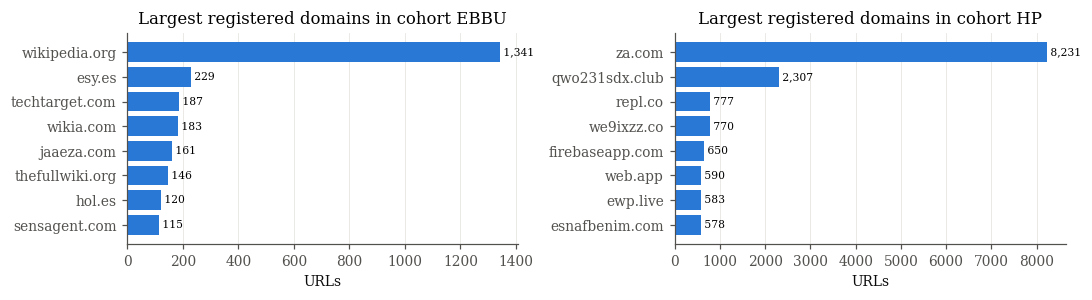

In [13]:
fig = viz.plot_top_groups(AUDIT); plt.show()

## Part 3 · Group-disjoint splits
Whole domains are assigned deterministically to FIT/VAL/TEST (≈60/20/20 %). FIT → selection and fitting,
VAL → thresholds only, TEST → read once, after the freeze.

### Step 3.1: Load the saved split and feature metadata



> **What to check:** class prevalence is nearly identical across FIT/VAL/TEST within a source.

In [14]:
from phishresearch.prepare import load_dev
stage("prepare", P.processed / "dev_features.parquet", P.artifacts / "prepare.json", P.processed / "splits.parquet")
PREP = read_json(P.artifacts / "prepare.json")
viz.partitions_table(PREP)

[prepare] saved artefacts verified: data\processed\dev_features.parquet, artifacts\prepare.json, data\processed\splits.parquet


,frac,groups,n,prevalence
source/partition,,,,
A/FIT,60.0%,8018,28061,52.6%
A/TEST,20.0%,6447,9353,52.6%
A/VAL,20.0%,6448,9355,52.6%
B/FIT,60.0%,2614,45050,60.4%
B/TEST,20.0%,2061,15013,60.4%
B/VAL,20.0%,2060,15014,60.4%


### Step 3.2: Verify that partitions share no domain



> **What to check:** every cell is 0 (the helper raises if not).

In [15]:
viz.check_group_disjoint(pd.read_parquet(P.processed / "splits.parquet", columns=["dataset_id", "group_id", "partition"]))

source,EBBU,HP
pair,,
FIT∩TEST,0,0
FIT∩VAL,0,0
VAL∩TEST,0,0


### Step 3.3: Demonstrate the TEST loader policy

The development loader refuses TEST; TEST labels live in a separate vault file (a procedural control).

In [16]:
try:
    load_dev(P, "A", "TEST")
except GateError as e:
    print("refused:", e)

refused: development loader refuses partition 'TEST'; TEST is read only by `evaluate`


## Part 4 · Lexical features
37 deterministic features computed from the URL string only (no network). Examples use reserved documentation domains.

### Step 4.1: Canonicalisation and grouping

Scheme/host are lower-cased and IDNA-encoded; path, query and fragment keep their case; default ports are kept; invalid inputs are quarantined with a reason.

In [17]:
DEMO = ["http://login.secure.example.com:8080/a_b/c-d?x=1&y=%41#top", "example.org/blog/post", "https://bücher.example/verify-account", "http://192.0.2.10/wallet/update.php?id=7", "HTTP://WWW.Example.CO.UK:80/Path", "javascript:alert(1)", "http://bad.example.test:99999/"]
viz.parse_demo(DEMO)

,result,url_key / reason,group (registered domain)
url,,,
http://login.secure.example.com:8080/a_b/c-d?x=1&y=%41#top,ParsedURL,http://login.secure.example.com:8080/a_b/c-d?x=1&y=%41#top,example.com
example.org/blog/post,ParsedURL,<none>://example.org/blog/post,example.org
https://bücher.example/verify-account,ParsedURL,https://xn--bcher-kva.example/verify-account,xn--bcher-kva.example
http://192.0.2.10/wallet/update.php?id=7,ParsedURL,http://192.0.2.10/wallet/update.php?id=7,ip:192.0.2.10
HTTP://WWW.Example.CO.UK:80/Path,ParsedURL,http://www.example.co.uk:80/Path,example.co.uk
javascript:alert(1),Quarantine,unsupported_scheme,n/a
http://bad.example.test:99999/,Quarantine,invalid_port,n/a


### Step 4.2: Feature values for valid examples

In [18]:
viz.feature_demo(DEMO[:5])

,http://login.secure.example.com:808…,example.org/blog/post,https://bücher.example/verify-account,http://192.0.2.10/wallet/update.php…,HTTP://WWW.Example.CO.UK:80/Path
F01 url_length,58.0000,21.0000,37.0000,40.0000,32.0000
F02 host_length,24.0000,11.0000,21.0000,10.0000,17.0000
F03 path_length,8.0000,10.0000,15.0000,18.0000,5.0000
F04 query_length,9.0000,0.0000,0.0000,4.0000,0.0000
F05 fragment_length,3.0000,0.0000,0.0000,0.0000,0.0000
F06 dot_count,3.0000,1.0000,1.0000,4.0000,3.0000
F07 hyphen_count,1.0000,0.0000,1.0000,0.0000,0.0000
F08 underscore_count,1.0000,0.0000,0.0000,0.0000,0.0000
F09 slash_count,4.0000,2.0000,3.0000,4.0000,3.0000
F10 at_count,0.0000,0.0000,0.0000,0.0000,0.0000


### Step 4.3: Subset extraction equals projection of ALL

A selected subset runs only the feature functions it needs (dependency pruning) yet yields identical values.

In [19]:
from phishresearch.features import extract_features
sub = ["F02", "F20", "F36"]
assert np.array_equal(extract_features(DEMO[:5], sub).to_numpy(), extract_features(DEMO[:5])[sub].to_numpy())
print("subset == projection of ALL for", sub)

subset == projection of ALL for ['F02', 'F20', 'F36']


## Part 5 · Source-only development
Per source and seed: 3 outer **domain** folds of FIT → permutation importance (PI) from outer-train only →
classifier on top-*k* → outer AP → smallest *k* within 0.01 AP of the best → PI on full FIT → final models →
thresholds locked on source VAL. TEST is never touched.

### Step 5.1: Load development outputs for both sources

No fitting is performed.

In [20]:
for s in "AB":
    stage(f"develop {s}", P.dev / s / "develop.json", P.dev / s / "outer_cv.csv")
DEV = {s: read_json(P.dev / s / "develop.json") for s in "AB"}

[develop A] saved artefacts verified: artifacts\dev\A\develop.json, artifacts\dev\A\outer_cv.csv
[develop B] saved artefacts verified: artifacts\dev\B\develop.json, artifacts\dev\B\outer_cv.csv


### Step 5.2: Chosen feature budget k

Selected per source × classifier × selector × seed.

> **What to check:** k is identical for both selectors here, so the matched-k contrast compares the rankings directly.

In [21]:
viz.chosen_k_table(DEV)

EBBU                      HP                
                 seed 17 seed 29 seed 43 seed 17 seed 29 seed 43
model / selector                                                
LGBM/MEAN_PI          16      16      16       8       8       8
LGBM/STABLE_PI        16      16      16       8       8       8
RF/MEAN_PI            16      16      16       8       8       8
RF/STABLE_PI          16      16      16       8       8       8

### Step 5.3: Nested-CV evidence behind the choice of k

Mean ± sd of outer hold-out AP across the 3 outer folds (seed 17 … 43 pooled).

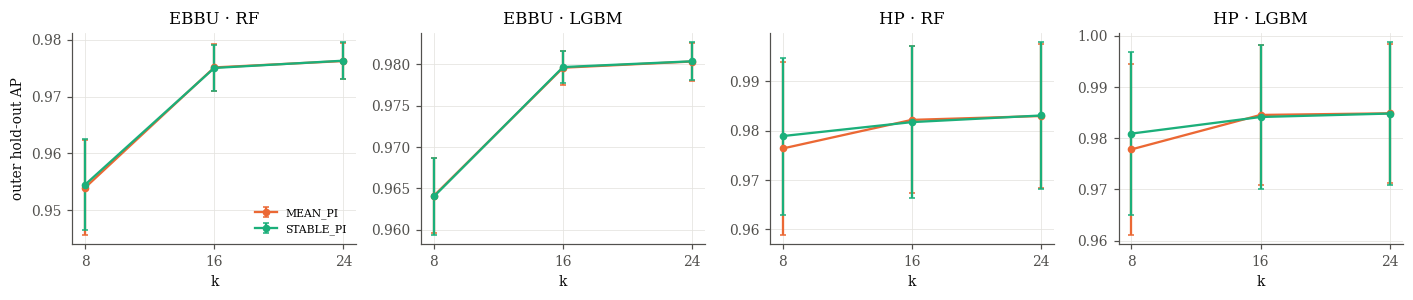

In [22]:
fig = viz.plot_outer_cv(P, CFG["selection"]["k_candidates"]); plt.show()

### Step 5.4: Permutation importance on full FIT

Bars = mean PI over folds and seeds; green = feature in the top-12 with positive PI in all three domain folds in every seed.

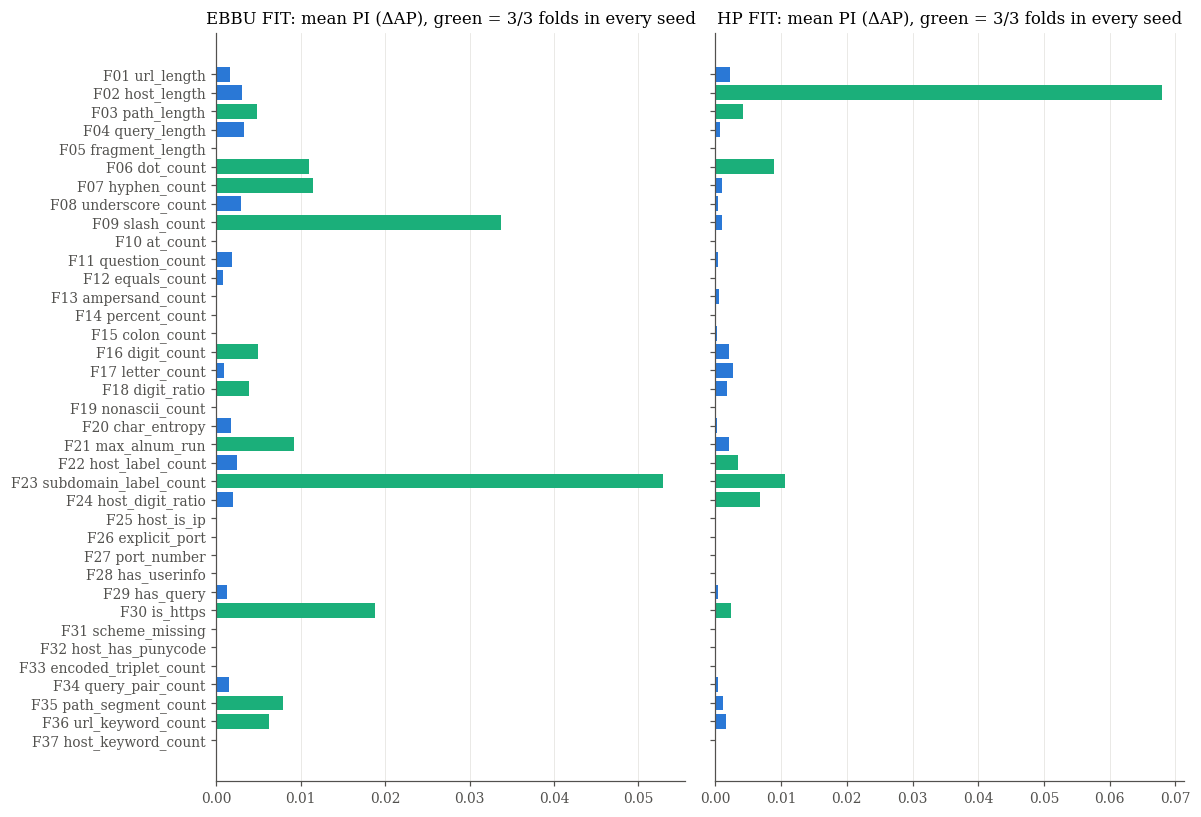

In [23]:
fig = viz.plot_pi(P, DEV, CFG["selection"]["q"]); plt.show()

### Step 5.5: Selected feature subsets (seed 17)

In [24]:
viz.selected_features_table(P)

roles                                                         features
source model selector  k                                                                                  
EBBU   LGBM  MEAN_PI   16  budget+matched  F02 F03 F04 F06 F07 F08 F09 F16 F18 F21 F22 F23 F24 F30 F35 F36
             STABLE_PI 16  budget+matched  F02 F03 F04 F06 F07 F08 F09 F16 F18 F21 F22 F23 F24 F30 F35 F36
       RF    MEAN_PI   16  budget+matched  F02 F03 F04 F06 F07 F08 F09 F16 F18 F21 F22 F23 F24 F30 F35 F36
             STABLE_PI 16  budget+matched  F02 F03 F04 F06 F07 F08 F09 F16 F18 F21 F22 F23 F24 F30 F35 F36
HP     LGBM  MEAN_PI   8   budget+matched                                  F02 F03 F06 F17 F21 F22 F23 F24
             STABLE_PI 8   budget+matched                                  F02 F03 F06 F21 F22 F23 F24 F30
       RF    MEAN_PI   8   budget+matched                                  F02 F03 F06 F17 F21 F22 F23 F24
             STABLE_PI 8   budget+matched                                  F02 F03 F06 F21 F22 F23 F24 F30

### Step 5.6: Compute cost of development and nested-selection integrity



> **What to check:** the last row is True: the selector used for the final model is never the one evaluated in outer CV.

In [25]:
viz.timing_table(DEV)

,EBBU,HP
PI computation (min),26.0765,10.5708
outer-CV classifier fits (min),2.146,2.4838
final fits (s),29.4209,27.6568
full-FIT selector ≠ outer selectors,True,True


## Part 6 · Freeze
Before any TEST label is read, a manifest hashes configs, code (except presentation modules), PSL, records, splits,
feature files, the TEST vault and **all 36 model bundles of both directions**.

### Step 6.1: Verify the existing freeze

A notebook cannot approve or replace the research freeze.

In [26]:
stage("freeze", P.freeze)
FREEZE = verify_freeze(P.freeze, ROOT)
pd.Series({"freeze hash": FREEZE["freeze_hash"], "approved by": FREEZE["approved_by"], "created": FREEZE["created_at"],
           "git commit": FREEZE["git_commit"], "files hashed": len(FREEZE["body"]["file_hashes"]), "bundles": len(FREEZE["body"]["plan"]),
           "verification": "PASSED"}).to_frame("value")

[freeze] saved artefacts verified: artifacts\freeze.json


,value
freeze hash,069912e332d788120e4ba358b1f8cd3dc5f0903d783249a87567ce00d6efc8da
approved by,Claude agent on behalf of the author (user instruction 2026-11-15)
created,2026-11-15T14:14:16+00:00
git commit,1111efdf19b65e1c489d0d96632b069d25af4d6f
files hashed,133
bundles,36
verification,PASSED


### Step 6.2: Tamper demonstration

A modified copy of the manifest is rejected (the real manifest is not touched).

In [27]:
bad = copy.deepcopy(FREEZE); bad["body"]["seeds"] = [1]
with tempfile.TemporaryDirectory() as td:
    fp = Path(td) / "freeze.json"; fp.write_text(json.dumps(bad), encoding="utf-8")
    try: verify_freeze(fp, ROOT)
    except GateError as e: print("rejected:", e)

rejected: freeze manifest body was modified


## Part 7 · Final evaluation (one batch)
Every frozen bundle is scored on its own source TEST and on the other source's TEST with the **same** VAL-locked threshold.

### Step 7.1: Verify and load the saved evaluation

Prediction bytes are hashed without reading individual TEST labels.

In [28]:
import pyarrow.parquet as pq
EVAL = viz.verify_saved_evaluation(P, FREEZE)
MET = pd.DataFrame(EVAL["metrics"])
n_predictions = pq.ParquetFile(P.eval / "predictions.parquet").metadata.num_rows
print(f"{EVAL['run_id']}: {n_predictions:,} predictions, {len(MET)} metric rows, status = {EVAL['status']}")

eval-069912e332d7: 877,176 predictions, 216 metric rows, status = completed


### Step 7.2: Inspect the saved metric-recomputation check

The analysis already recomputed every metric. Show its aggregate check after verifying prediction integrity; no labels are loaded here.

> **What to check:** `max_abs_diff` is 0.0.

In [29]:
CHECK = read_json(P.analysis / "checks.json")["I06_recompute"]
if CHECK["status"] != "pass" or CHECK["rows_checked"] != len(MET) or CHECK["max_abs_diff"] != 0:
    raise GateError("Saved metric-recomputation check failed or is incomplete")
CHECK

{'max_abs_diff': 0.0, 'rows_checked': 216, 'status': 'pass'}

## Part 8 · Analysis
Cluster-bootstrap CIs (domains resampled), the four pre-specified contrasts, transfer drop, latency benchmark and SHAP.

### Step 8.1: Load the completed analysis

Incomplete runs are preserved. Recovery provenance is shown when saved SHAP outputs were reused.

In [30]:
stage("analyze", *(P.analysis / n for n in ("results_registry.json", "summary.csv", "config_ci.csv", "contrasts.json",
                                          "transfer_drop.csv", "benchmark.csv", "benchmark.json", "shap_summary.csv",
                                          "shap_compare.csv", "shap_mean_abs.csv")))
A = P.analysis
ANALYSIS = read_json(A / "results_registry.json")
if ANALYSIS["freeze_hash"] != FREEZE["freeze_hash"] or ANALYSIS["run_id"] != EVAL["run_id"]:
    raise GateError("Analysis belongs to another frozen evaluation")
recovery_path = A / ANALYSIS.get("recovery_provenance", "recovery.json")
if recovery_path.is_file():
    recovery = read_json(recovery_path)
    display(pd.Series({k: recovery[k] for k in ("source", "method", "shap_arrays_checked", "additivity_failures",
                                               "max_additivity_error", "individual_test_labels_read")}))
MAIN = viz.main_frame(A)
ANALYSIS["status"]

[analyze] saved artefacts verified: artifacts\analysis\results_registry.json, artifacts\analysis\summary.csv, artifacts\analysis\config_ci.csv, artifacts\analysis\contrasts.json, artifacts\analysis\transfer_drop.csv, artifacts\analysis\benchmark.csv, artifacts\analysis\benchmark.json, artifacts\analysis\shap_summary.csv, artifacts\analysis\shap_compare.csv, artifacts\analysis\shap_mean_abs.csv


source                                  artifacts/analysis_run1_contaminated_benchmark
method                         verified reuse of saved SHAP; active benchmark retained
shap_arrays_checked                                                                 24
additivity_failures                                                                  4
max_additivity_error                                                            0.0033
individual_test_labels_read                                                      False
dtype: object

{'benchmark': 'completed', 'evaluation': 'completed', 'shap': 'completed'}

### RQ1: internal vs cross-dataset performance

### Step 8.2: F1 with 95 % domain-cluster CI

Primary threshold policy = F1-max on source VAL; mean over 3 seeds.

In [31]:
viz.results_table(MAIN)

config                              ALL        MEAN_PI@budget      STABLE_PI@budget
cell        model                                                                  
EBBU → EBBU LGBM   0.902 [0.894, 0.909]  0.900 [0.893, 0.908]  0.900 [0.892, 0.907]
            RF     0.895 [0.887, 0.902]  0.897 [0.889, 0.904]  0.896 [0.889, 0.903]
EBBU → HP   LGBM   0.922 [0.910, 0.933]  0.916 [0.903, 0.927]  0.915 [0.902, 0.927]
            RF     0.917 [0.905, 0.929]  0.914 [0.901, 0.925]  0.913 [0.901, 0.924]
HP → HP     LGBM   0.958 [0.949, 0.966]  0.942 [0.932, 0.951]  0.946 [0.937, 0.955]
            RF     0.956 [0.947, 0.964]  0.941 [0.930, 0.950]  0.944 [0.933, 0.953]
HP → EBBU   LGBM   0.790 [0.779, 0.800]  0.619 [0.605, 0.634]  0.697 [0.685, 0.709]
            RF     0.739 [0.727, 0.751]  0.639 [0.625, 0.652]  0.697 [0.685, 0.710]

### Step 8.3: Visual comparison of the four evaluation cells

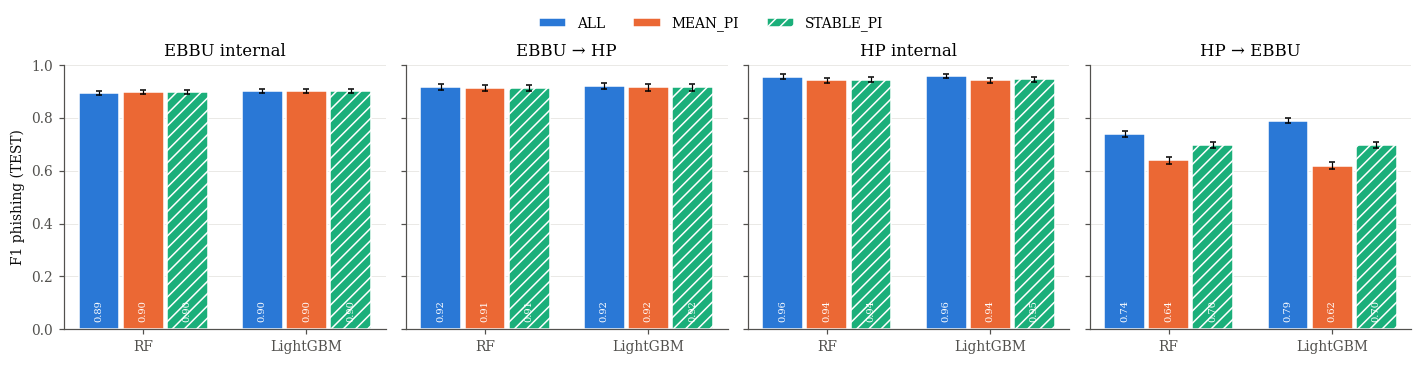

In [32]:
fig = viz.plot_f1(MAIN); plt.show()

### Step 8.4: Transfer drop

F1(source TEST) − F1(target TEST), same model and threshold; percentage points.

> **What to check:** a negative drop means the model scored *higher* on the other source.

In [33]:
viz.transfer_table(A)

f1_source  f1_target  drop_pp  drop_sd
source    model config                                                   
EBBU → HP LGBM  ALL                    0.902      0.922   -2.035    0.000
                MEAN_PI@budget         0.900      0.916   -1.542    0.009
                MEAN_PI@matched        0.900      0.916   -1.542    0.009
                STABLE_PI@budget       0.900      0.915   -1.559    0.038
                STABLE_PI@matched      0.900      0.915   -1.559    0.038
          RF    ALL                    0.895      0.917   -2.269    0.250
                MEAN_PI@budget         0.897      0.914   -1.695    0.283
                MEAN_PI@matched        0.897      0.914   -1.695    0.283
                STABLE_PI@budget       0.896      0.913   -1.735    0.213
                STABLE_PI@matched      0.896      0.913   -1.735    0.213
HP → EBBU LGBM  ALL                    0.958      0.790   16.874    0.000
                MEAN_PI@budget         0.942      0.619   32.261    3.951
                MEAN_PI@matched        0.942      0.619   32.261    3.951
                STABLE_PI@budget       0.946      0.697   24.966    0.218
                STABLE_PI@matched      0.946      0.697   24.966    0.218
          RF    ALL                    0.956      0.739   21.693    1.384
                MEAN_PI@budget         0.941      0.639   30.229    3.830
                MEAN_PI@matched        0.941      0.639   30.229    3.830
                STABLE_PI@budget       0.944      0.697   24.677    0.678
                STABLE_PI@matched      0.944      0.697   24.677    0.678

### Step 8.5: All metrics (primary threshold)

Includes MCC, ROC-AUC, AP and the domain-balanced F1 (each domain weighted equally).

In [34]:
viz.metric_table(A)

,,,k_per_seed,f1,precision,recall,specificity,mcc,balanced_accuracy,roc_auc,average_precision,fpr,f1_domain_balanced
cell,model,config,,,,,,,,,,,
EBBU → EBBU,LGBM,ALL,37 37 37,0.902,0.889,0.914,0.874,0.789,0.894,0.961,0.966,0.126,0.872
EBBU → HP,LGBM,ALL,37 37 37,0.922,0.962,0.885,0.946,0.819,0.916,0.960,0.958,0.054,0.796
EBBU → EBBU,LGBM,MEAN_PI@budget,16 16 16,0.900,0.901,0.900,0.890,0.790,0.895,0.960,0.965,0.110,0.873
EBBU → HP,LGBM,MEAN_PI@budget,16 16 16,0.916,0.960,0.875,0.945,0.806,0.910,0.958,0.956,0.055,0.778
EBBU → EBBU,LGBM,STABLE_PI@budget,16 16 16,0.900,0.901,0.899,0.890,0.789,0.894,0.960,0.965,0.110,0.873
EBBU → HP,LGBM,STABLE_PI@budget,16 16 16,0.915,0.961,0.874,0.946,0.806,0.910,0.958,0.956,0.054,0.776
EBBU → EBBU,RF,ALL,37 37 37,0.895,0.879,0.911,0.860,0.774,0.886,0.957,0.962,0.140,0.862
EBBU → HP,RF,ALL,37 37 37,0.917,0.956,0.882,0.939,0.808,0.910,0.952,0.947,0.061,0.782
EBBU → EBBU,RF,MEAN_PI@budget,16 16 16,0.897,0.884,0.910,0.867,0.779,0.889,0.957,0.962,0.133,0.865


### Step 8.6: Operating point with ≤1 % FPR on source VAL

The VAL-locked low-FPR threshold applied to TEST: recall and the *achieved* FPR (which may exceed 1 % on the target).

In [35]:
viz.metric_table(A, "fpr_le")[["recall", "precision", "fpr", "f1"]]

,,,recall,precision,fpr,f1
cell,model,config,,,,
EBBU → EBBU,LGBM,ALL,0.559,0.986,0.009,0.713
EBBU → HP,LGBM,ALL,0.345,0.971,0.016,0.509
EBBU → EBBU,LGBM,MEAN_PI@budget,0.553,0.984,0.010,0.708
EBBU → HP,LGBM,MEAN_PI@budget,0.510,0.978,0.018,0.671
EBBU → EBBU,LGBM,STABLE_PI@budget,0.549,0.984,0.010,0.705
EBBU → HP,LGBM,STABLE_PI@budget,0.482,0.977,0.017,0.644
EBBU → EBBU,RF,ALL,0.475,0.986,0.007,0.641
EBBU → HP,RF,ALL,0.017,0.898,0.003,0.034
EBBU → EBBU,RF,MEAN_PI@budget,0.478,0.985,0.008,0.644


### RQ2: does stability-based selection transfer better?

### Step 8.7: Primary contrasts: STABLE_PI − MEAN_PI at matched k (target TEST)

Paired domain-cluster bootstrap (2,000 replicates); the same resampled domains are used for both arms and all seeds.

In [36]:
CON = read_json(A / "contrasts.json"); F1ABS = CFG["effects"]["f1_abs"]
PRIMARY = viz.contrast_frame(CON["primary"], F1ABS); PRIMARY

,cell,model,contrast,k (a | b),ΔF1,CI low,CI high,per seed,same model,|Δ| ≥ 0.01,verdict
0,EBBU → HP,RF,STABLE_PI@matched − MEAN_PI@matched,"[16, 16, 16] | [16, 16, 16]",-0.0005,-0.0012,0.0003,"[0.0, 0.0025, -0.0039]",False,False,CI includes 0
1,EBBU → HP,LGBM,STABLE_PI@matched − MEAN_PI@matched,"[16, 16, 16] | [16, 16, 16]",-0.0002,-0.0007,0.0003,"[0.0, -0.0018, 0.0011]",False,False,CI includes 0
2,HP → EBBU,RF,STABLE_PI@matched − MEAN_PI@matched,"[8, 8, 8] | [8, 8, 8]",0.0586,0.0511,0.0664,"[0.0951, 0.0143, 0.0664]",False,True,CI > 0
3,HP → EBBU,LGBM,STABLE_PI@matched − MEAN_PI@matched,"[8, 8, 8] | [8, 8, 8]",0.0773,0.0691,0.0859,"[0.0734, 0.039, 0.1195]",False,True,CI > 0


### Step 8.8: Forest plot of the primary contrasts

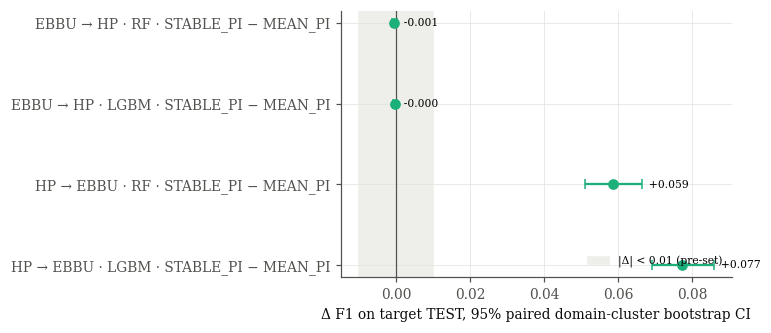

In [37]:
fig = viz.plot_contrasts(PRIMARY, F1ABS); plt.show()

### Step 8.9: Secondary contrasts (cross-dataset)

STABLE vs ALL, MEAN vs ALL, STABLE vs MEAN at the selected budget.

In [38]:
SECONDARY = viz.contrast_frame([c for c in CON["secondary"] if c["source"] != c["target"]], F1ABS)
SECONDARY

,cell,model,contrast,k (a | b),ΔF1,CI low,CI high,per seed,same model,|Δ| ≥ 0.01,verdict
0,EBBU → HP,RF,STABLE_PI@budget − ALL,"[16, 16, 16] | [37, 37, 37]",-0.0042,-0.0061,-0.0025,"[-0.0007, -0.0024, -0.0095]",False,False,CI < 0
1,EBBU → HP,RF,MEAN_PI@budget − ALL,"[16, 16, 16] | [37, 37, 37]",-0.0037,-0.0054,-0.0021,"[-0.0007, -0.0049, -0.0056]",False,False,CI < 0
2,EBBU → HP,RF,STABLE_PI@budget − MEAN_PI@budget,"[16, 16, 16] | [16, 16, 16]",-0.0005,-0.0012,0.0003,"[0.0, 0.0025, -0.0039]",False,False,CI includes 0
3,EBBU → HP,LGBM,STABLE_PI@budget − ALL,"[16, 16, 16] | [37, 37, 37]",-0.0067,-0.0092,-0.0044,"[-0.007, -0.007, -0.0059]",False,False,CI < 0
4,EBBU → HP,LGBM,MEAN_PI@budget − ALL,"[16, 16, 16] | [37, 37, 37]",-0.0064,-0.0089,-0.0041,"[-0.007, -0.0053, -0.007]",False,False,CI < 0
5,EBBU → HP,LGBM,STABLE_PI@budget − MEAN_PI@budget,"[16, 16, 16] | [16, 16, 16]",-0.0002,-0.0007,0.0003,"[0.0, -0.0018, 0.0011]",False,False,CI includes 0
6,HP → EBBU,RF,STABLE_PI@budget − ALL,"[8, 8, 8] | [37, 37, 37]",-0.0415,-0.0495,-0.0330,"[-0.0481, -0.0271, -0.0495]",False,True,CI < 0
7,HP → EBBU,RF,MEAN_PI@budget − ALL,"[8, 8, 8] | [37, 37, 37]",-0.1001,-0.1085,-0.0916,"[-0.1431, -0.0414, -0.1159]",False,True,CI < 0
8,HP → EBBU,RF,STABLE_PI@budget − MEAN_PI@budget,"[8, 8, 8] | [8, 8, 8]",0.0586,0.0511,0.0664,"[0.0951, 0.0143, 0.0664]",False,True,CI > 0
9,HP → EBBU,LGBM,STABLE_PI@budget − ALL,"[8, 8, 8] | [37, 37, 37]",-0.0928,-0.1009,-0.0846,"[-0.0927, -0.0927, -0.0928]",False,True,CI < 0


### Step 8.10: Forest plot of the secondary contrasts

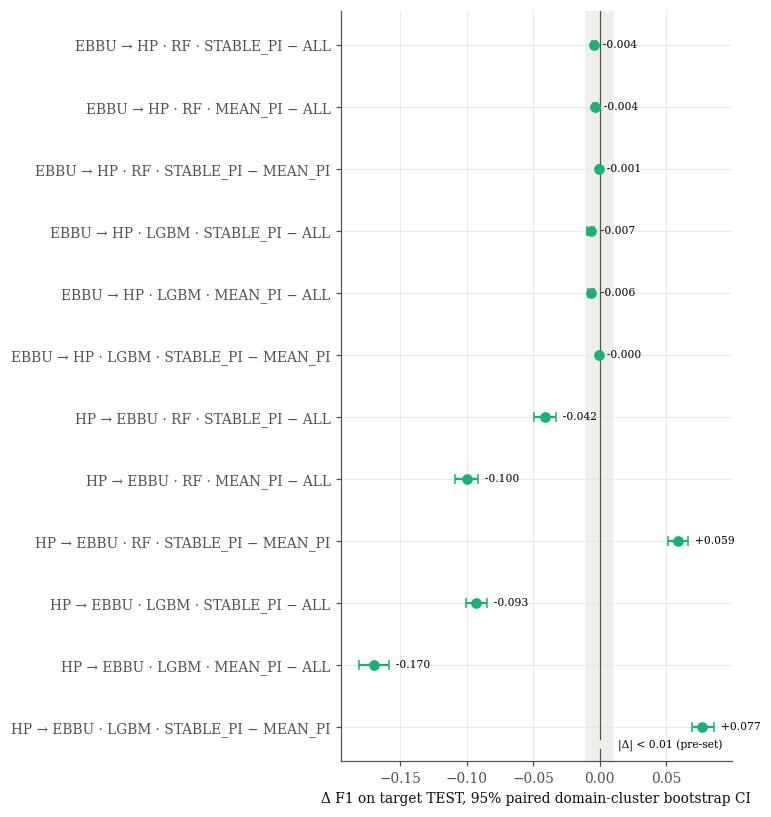

In [39]:
fig = viz.plot_contrasts(SECONDARY, F1ABS); plt.show()

### RQ3: computational cost

### Step 8.11: Latency per URL by stage

Median µs per URL; parse+features, predict-only and end-to-end; 1 and 4 inference threads.

In [40]:
viz.cost_table(A)

t1/batch1/end_to_end  t1/batch1/extract  t1/batch1/predict  t1/batch1024/end_to_end  t1/batch1024/extract  t1/batch1024/predict  t4/batch1/end_to_end  t4/batch1/extract  \
source model selector  k                                                                                                                                                                              
A      LGBM  ALL       37                1166.9              251.5              908.2                    120.6                  94.3                  28.4                1280.8              200.6   
             MEAN_PI   16                 888.2              171.6              820.6                     77.6                  52.0                  24.4                1220.8              157.5   
             STABLE_PI 16                 881.0              176.6              598.4                     73.9                  55.8                  19.5                1116.2              125.1   
       RF    ALL       37               12093.8              155.2            10243.7                    138.1                  79.4                  59.0               47167.5              159.3   
             MEAN_PI   16                9995.2              130.6             9880.8                    103.8                  47.1                  50.6               47251.3              110.7   
             STABLE_PI 16               10110.0              112.0             9574.8                     96.3                  44.1                  50.9               47047.8              122.8   
B      LGBM  ALL       37                 830.3              228.4              555.9                     95.0                  85.6                  19.1                1195.1              132.0   
             MEAN_PI   8                  772.4              149.8              539.2                     53.0                  37.0                  17.2                1092.9              135.0   
             STABLE_PI 8                  721.2              145.9              486.5                     51.8                  29.0                  17.3                1063.8               84.8   
       RF    ALL       37                9852.5              149.8             9356.2                    123.9                  74.4                  48.6               46976.6              168.6   
             MEAN_PI   8                10795.4              105.2            10316.0                     89.9                  36.8                  49.5               62504.8              112.4   
             STABLE_PI 8                10455.4              110.9            10703.6                     73.9                  29.2                  44.5               47632.0              100.7   

                           t4/batch1/predict  t4/batch1024/end_to_end  t4/batch1024/extract  t4/batch1024/predict  
source model selector  k                                                                                           
A      LGBM  ALL       37              924.2                    112.5                  80.7                   7.8  
             MEAN_PI   16              872.0                     74.3                  53.5                   7.4  
             STABLE_PI 16              816.8                     75.0                  53.8                   7.0  
       RF    ALL       37            61393.5                    150.3                  77.8                  75.9  
             MEAN_PI   16            46925.2                    122.2                  45.8                  76.5  
             STABLE_PI 16            47020.9                    121.0                  48.3                  75.3  
B      LGBM  ALL       37              823.0                    111.3                  73.5                   7.3  
             MEAN_PI   8               769.2                     61.0                  36.5                   6.7  
             STABLE_PI 8               762.2                     52.6           

### Step 8.12: End-to-end latency relative to ALL

< 0.90 would be a ≥10 % reduction (the pre-set practical threshold).

In [41]:
viz.relative_latency_table(A)

1 thread · batch1  1 thread · batch1024  4 thread · batch1  4 thread · batch1024
source model selector  k                                                                                   
A      LGBM  ALL       37              1.000                 1.000              1.000                 1.000
             MEAN_PI   16              0.761                 0.644              0.953                 0.661
             STABLE_PI 16              0.755                 0.613              0.871                 0.667
       RF    ALL       37              1.000                 1.000              1.000                 1.000
             MEAN_PI   16              0.826                 0.751              1.002                 0.813
             STABLE_PI 16              0.836                 0.697              0.997                 0.805
B      LGBM  ALL       37              1.000                 1.000              1.000                 1.000
             MEAN_PI   8               0.930                 0.558              0.915                 0.548
             STABLE_PI 8               0.869                 0.546              0.890                 0.473
       RF    ALL       37              1.000                 1.000              1.000                 1.000
             MEAN_PI   8               1.096                 0.725              1.331                 1.006
             STABLE_PI 8               1.061                 0.597              1.014                 0.614

### Step 8.13: Where the time goes

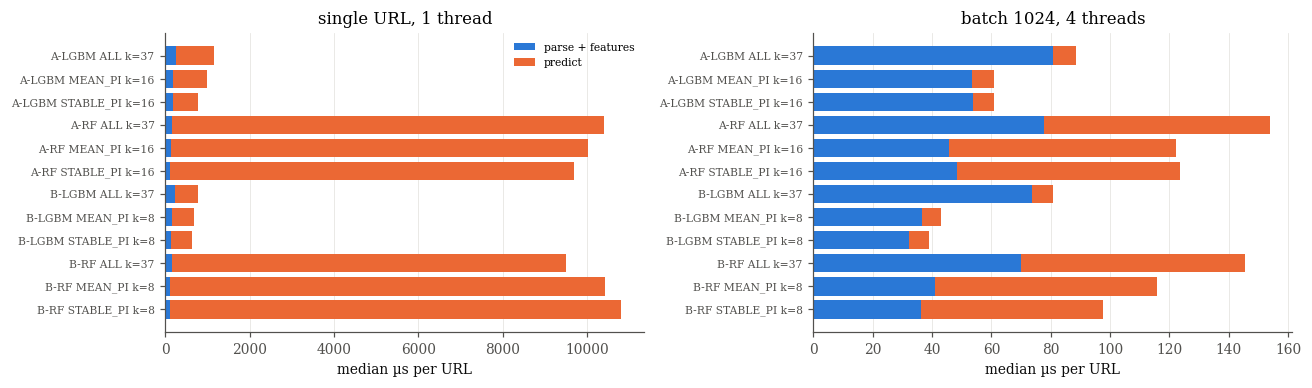

In [42]:
fig = viz.plot_latency(A); plt.show()

### Step 8.14: Model size, load and training time

In [43]:
viz.size_table(A)

,features,model MB,load ms,fit s,RSS Δ MB
bundle,,,,,
A-LGBM-ALL-k37-s17,37,1.00,11.26,0.77,2.94
A-LGBM-MEAN_PI-k16-s17,16,0.99,9.63,0.62,1.00
A-LGBM-STABLE_PI-k16-s17,16,0.99,8.32,0.63,0.01
A-RF-ALL-k37-s17,37,56.45,149.50,3.12,61.84
A-RF-MEAN_PI-k16-s17,16,55.75,139.07,2.74,63.25
A-RF-STABLE_PI-k16-s17,16,55.75,169.30,2.68,63.63
B-LGBM-ALL-k37-s17,37,1.00,8.61,0.86,2.12
B-LGBM-MEAN_PI-k8-s17,8,0.99,9.65,0.55,2.00
B-LGBM-STABLE_PI-k8-s17,8,0.99,9.05,0.54,0.31


### RQ4: what the models rely on (SHAP)

### Step 8.15: SHAP integrity and rank agreement

TreeExplainer on the actual models (interventional, probability output). Spearman ρ and top-10 Jaccard compare source vs target rankings and, for ALL, rankings across seeds.

In [44]:
SS = pd.read_csv(A / "shap_summary.csv"); SC = pd.read_csv(A / "shap_compare.csv")
SHAP_A = A
print(f"max additivity error = {SS.additivity_max_abs_err.max():.1e}")
SHAP_FAILURES = SS[SS.additivity_max_abs_err > 1e-6]
if len(SHAP_FAILURES):
    display(Markdown(f"**SHAP validation warning:** {len(SHAP_FAILURES)}/{len(SS)} saved explanations exceed the existing 1e-6 "
                     "additivity tolerance. RQ4 is diagnostic; I09 is not passed for these real-data outputs. See D-24."))
    display(SHAP_FAILURES[["bundle_id", "cohort", "additivity_max_abs_err"]])

correction = viz.verify_shap_correction(P, FREEZE)
if correction is not None:
    SHAP_A, correction_manifest = correction
    SS = pd.read_csv(SHAP_A / "shap_summary.csv")
    SC = pd.read_csv(SHAP_A / "shap_compare.csv")
    SHAP_FAILURES = SS[SS.additivity_max_abs_err > 1e-6]
    display(Markdown(f"**Exploratory correction (D-36): {len(SS)}/{len(SS)} cohorts passed strict additivity.** "
                     f"Maximum residual {SS.additivity_max_abs_err.max():.2e}. The fitted models, thresholds and saved "
                     "classification results remain unchanged. The preceding warning belongs to preserved v1 outputs. "
                     "Plots and RQ4 summaries below use the corrected explanations; additivity alone does not establish faithfulness."))
    display(SS[["bundle_id", "cohort", "old_additivity_max_abs_err", "additivity_max_abs_err"]])
display(SC.round(3))

max additivity error = 3.3e-03


**SHAP validation warning:** 4/24 saved explanations exceed the existing 1e-6 additivity tolerance. RQ4 is diagnostic; I09 is not passed for these real-data outputs. See D-24.

,bundle_id,cohort,additivity_max_abs_err
0,A-RF-ALL-k37-s17,source,3.3333e-03
12,B-RF-ALL-k37-s17,source,1.3350e-05
13,B-RF-ALL-k37-s17,target,1.3350e-05
20,B-RF-ALL-k37-s29,source,2.5020e-03


**Exploratory correction (D-36): 24/24 cohorts passed strict additivity.** Maximum residual 2.95e-08. The fitted models, thresholds and saved classification results remain unchanged. The preceding warning belongs to preserved v1 outputs. Plots and RQ4 summaries below use the corrected explanations; additivity alone does not establish faithfulness.

,bundle_id,cohort,old_additivity_max_abs_err,additivity_max_abs_err
0,A-LGBM-ALL-k37-s17,source,6.4591e-09,6.4591e-09
1,A-LGBM-ALL-k37-s17,target,8.3093e-09,8.3093e-09
2,A-LGBM-ALL-k37-s29,source,6.4591e-09,6.4591e-09
3,A-LGBM-ALL-k37-s43,source,6.4591e-09,6.4591e-09
4,A-LGBM-STABLE_PI-k16-s17,source,6.4997e-09,6.4997e-09
5,A-LGBM-STABLE_PI-k16-s17,target,6.3384e-09,6.3384e-09
6,A-RF-ALL-k37-s17,source,3.3333e-03,2.5471e-08
7,A-RF-ALL-k37-s17,target,2.4765e-08,2.4766e-08
8,A-RF-ALL-k37-s29,source,2.5435e-08,2.5434e-08
9,A-RF-ALL-k37-s43,source,2.5187e-08,2.5191e-08


,bundle_id,model,source,config,kind,spearman,top10_jaccard
0,A-LGBM-ALL-k37-s17,LGBM,A,ALL,source_vs_target,0.992,0.818
1,A-LGBM-STABLE_PI-k16-s17,LGBM,A,STABLE_PI@budget,source_vs_target,0.882,0.818
2,A-RF-ALL-k37-s17,RF,A,ALL,source_vs_target,0.971,0.818
3,A-RF-STABLE_PI-k16-s17,RF,A,STABLE_PI@budget,source_vs_target,0.812,0.818
4,B-LGBM-ALL-k37-s17,LGBM,B,ALL,source_vs_target,0.958,0.818
5,B-LGBM-STABLE_PI-k8-s17,LGBM,B,STABLE_PI@budget,source_vs_target,0.976,1.000
6,B-RF-ALL-k37-s17,RF,B,ALL,source_vs_target,0.948,0.818
7,B-RF-STABLE_PI-k8-s17,RF,B,STABLE_PI@budget,source_vs_target,0.976,1.000
8,A-LGBM-ALL-k37-s17 vs A-LGBM-ALL-k37-s29,LGBM,A,ALL,seed_stability_source,1.000,1.000
9,A-LGBM-ALL-k37-s17 vs A-LGBM-ALL-k37-s43,LGBM,A,ALL,seed_stability_source,1.000,1.000


### Step 8.16: Top attributions, source vs target TEST (ALL, seed 17)

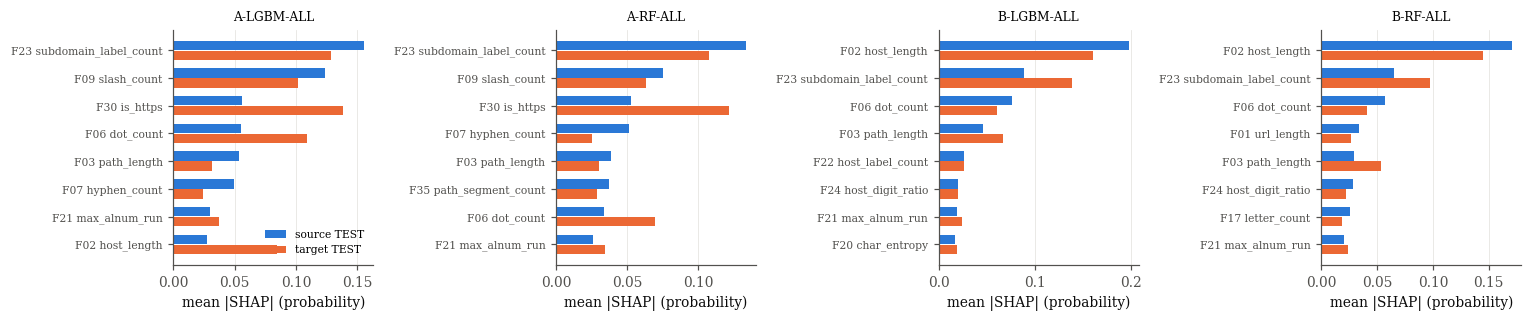

In [45]:
fig = viz.plot_shap_bars(SHAP_A); plt.show()

### Step 8.17: Beeswarm: LightGBM trained on HP, explained on HP TEST

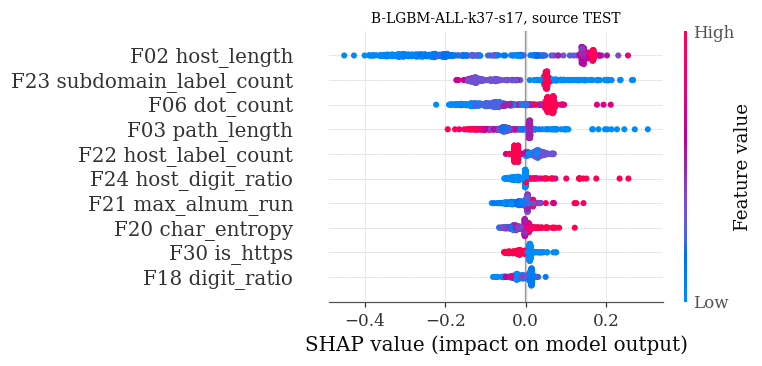

In [46]:
fig = viz.shap_beeswarm(SHAP_A, "B-LGBM-ALL-k37-s17", "source"); plt.show()

### Step 8.18: Beeswarm: the same model on EBBU TEST (target)

Same model, same background; only the input distribution changes.

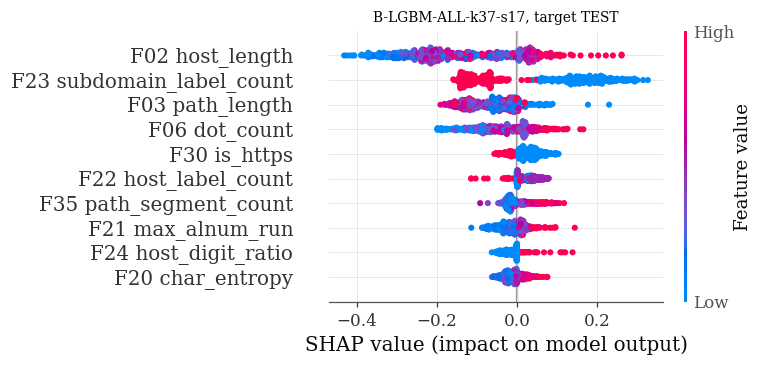

In [47]:
fig = viz.shap_beeswarm(SHAP_A, "B-LGBM-ALL-k37-s17", "target"); plt.show()

### RQ5 (exploratory): why does transfer fail where it does?

Added after the frozen evaluation and specified in `docs/decisions.md` **D-40** before running. Everything below
uses **FIT/VAL only**: baselines (logistic regression, a one-feature HTTPS rule), a no-HTTPS ablation, class-conditional
EDA and slice-level error analysis. Transfer is measured on the **target VAL** partition, which no model of that direction
has seen. TEST is not read. Produced by `python -m phishresearch.cli extend`.

### Step 8.19: Load the verified extension run

The run directory, its manifest and every output hash are checked before use.

> **What to check:** status = passed and test_labels_read = False.

In [48]:
from phishresearch.extensions.analysis import latest_run
from phishresearch.prepare import load_dev
EXT = latest_run(P)
EXT_MAN = json.loads((EXT / "manifest.json").read_text(encoding="utf-8"))
EXT_RES = json.loads((EXT / "results.json").read_text(encoding="utf-8"))
print(EXT.relative_to(ROOT))
pd.Series({k: EXT_MAN[k] for k in ("status", "decision", "partitions_used", "test_features_read", "test_labels_read", "dataset_urls_opened")})

artifacts\extensions\run_20261116T063740629948Z_fe541b37


status                     passed
decision                     D-40
partitions_used        [FIT, VAL]
test_features_read          False
test_labels_read            False
dataset_urls_opened         False
dtype: object

### Step 8.20: EDA: feature distributions per class and dataset (FIT)

Raw distributions of four interpretable features on source FIT. The same feature can separate the classes in opposite directions in the two collections.

> **What to check:** Subdomain labels: EBBU phishing is lower than benign, HP phishing is far higher. HTTPS is a benign cue in both.

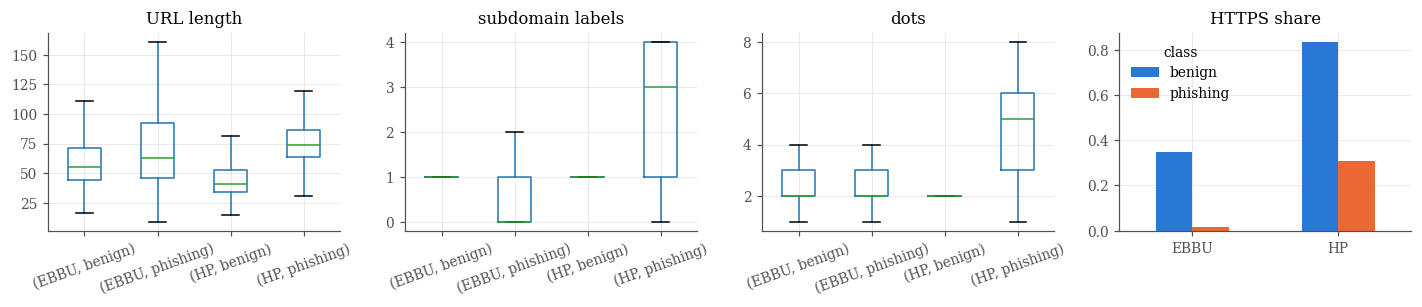

In [49]:
FIT = pd.concat([load_dev(P, s, "FIT").assign(dataset=viz.SRC_NAME[s]) for s in ("A", "B")])
FIT["class"] = FIT.label.map({0: "benign", 1: "phishing"})
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, (f, title) in zip(axes, [("F01", "URL length"), ("F23", "subdomain labels"), ("F06", "dots"), ("F30", "HTTPS share")]):
    if f == "F30":
        FIT.groupby(["dataset", "class"])[f].mean().unstack().plot.bar(ax=ax, rot=0, color=["#2a78d6", "#eb6834"])
    else:
        FIT.assign(v=FIT[f].clip(upper=FIT[f].quantile(0.99))).boxplot(column="v", by=["dataset", "class"], ax=ax, showfliers=False, rot=20)
    ax.set_title(title); ax.set_xlabel("")
plt.suptitle(""); fig.tight_layout(); plt.show()

### Step 8.21: EDA: class-conditional effect size (Cohen's d) in both sources

d = standardised mean difference phishing − benign on FIT. `sign_agrees = False` marks a reversed cue.

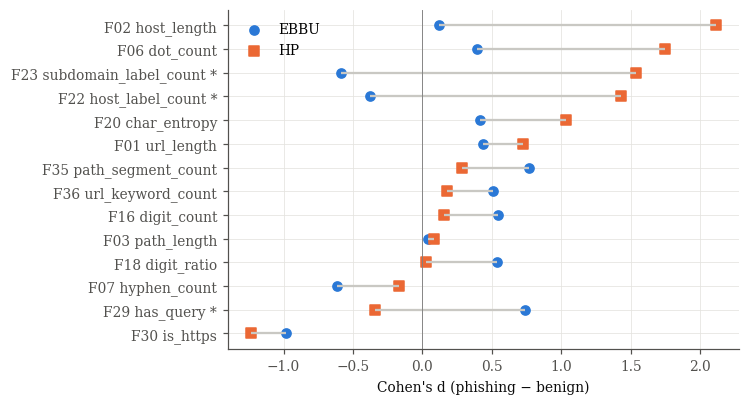

,feature,name,A_d,B_d,sign_agrees
0,F01,url_length,0.44,0.72,True
1,F02,host_length,0.12,2.11,True
2,F03,path_length,0.04,0.09,True
3,F06,dot_count,0.39,1.75,True
4,F07,hyphen_count,-0.61,-0.17,True
5,F16,digit_count,0.55,0.16,True
6,F18,digit_ratio,0.54,0.03,True
7,F20,char_entropy,0.42,1.04,True
8,F22,host_label_count,-0.38,1.43,False
9,F23,subdomain_label_count,-0.58,1.54,False


In [50]:
EDA = pd.read_csv(EXT / "eda.csv")
fig, ax = plt.subplots(figsize=(6, 4))
o = EDA.sort_values("B_d").reset_index(drop=True)
ax.hlines(o.index, o.A_d, o.B_d, color="#c9c8c3")
ax.scatter(o.A_d, o.index, label="EBBU", color="#2a78d6"); ax.scatter(o.B_d, o.index, label="HP", marker="s", color="#eb6834")
ax.set_yticks(o.index); ax.set_yticklabels([f"{r.feature} {r.name}{' *' if not r.sign_agrees else ''}" for r in o.itertuples()])
ax.axvline(0, color="grey", lw=.6); ax.set_xlabel("Cohen's d (phishing − benign)"); ax.legend(); plt.show()
EDA[["feature", "name", "A_d", "B_d", "sign_agrees"]].round(2)

### Step 8.22: Baselines and no-HTTPS ablation (source VAL vs target VAL)

Source-VAL F1 is optimistic (it also sets the threshold); target VAL is the honest transfer estimate. Frozen v1 models keep their frozen thresholds; LogReg and ablated models take theirs from source VAL.

> **What to check:** LogReg keeps AUC on the target but its F1 collapses at the source threshold; the HTTPS rule alone is strong on HP.

In [51]:
XM = pd.read_csv(EXT / "metrics.csv")
XM["direction"] = XM.source.map(lambda s: f"{viz.SRC_NAME[s]}→{viz.SRC_NAME['B' if s == 'A' else 'A']}")
XM.groupby(["direction", "config", "eval"])[["f1", "ap", "auc", "recall", "fpr"]].mean().round(3).unstack("eval")

f1                    ap                   auc                recall                   fpr           
eval                   source_val target_val source_val target_val source_val target_val source_val target_val source_val target_val
direction config                                                                                                                    
EBBU→HP   HTTPS-rule        0.739      0.874      0.593      0.858      0.618      0.855      0.976      0.845      0.740      0.135
          LGBM-ALL          0.909      0.928      0.967      0.972      0.964      0.968      0.925      0.898      0.124      0.057
          LGBM-noHTTPS      0.899      0.906      0.963      0.946      0.958      0.942      0.912      0.947      0.131      0.219
          LR-ALL            0.871      0.275      0.941      0.840      0.936      0.847      0.905      0.168      0.192      0.086
          RF-ALL            0.903      0.918      0.963      0.966      0.960      0.961      0.927      0.891      0.140      0.077
          RF-noHTTPS        0.897      0.898      0.957      0.921      0.954      0.933      0.920      0.958      0.147      0.267
HP→EBBU   HTTPS-rule        0.874      0.739      0.858      0.593      0.855      0.618      0.845      0.976      0.135      0.740
          LGBM-ALL          0.955      0.783      0.993      0.874      0.988      0.863      0.964      0.772      0.082      0.221
          LGBM-noHTTPS      0.956      0.716      0.993      0.852      0.987      0.834      0.959      0.638      0.072      0.160
          LR-ALL            0.929      0.666      0.979      0.749      0.965      0.763      0.899      0.589      0.057      0.199
          RF-ALL            0.951      0.734      0.991      0.826      0.986      0.821      0.950      0.672      0.073      0.176
          RF-noHTTPS        0.951      0.692      0.991      0.812      0.985      0.792      0.949      0.598      0.070      0.146

### Step 8.23: Sanity check: target VAL reproduces target TEST

If the VAL partition behaves like TEST, diagnostics computed on VAL describe the reported transfer.

In [52]:
v = XM[(XM.kind == "frozen_v1") & (XM["eval"] == "target_val")].groupby(["source", "model"]).f1.mean()
t = MAIN[(MAIN.config == "ALL") & (MAIN.source != MAIN.target)].set_index(["source", "model"]).f1_mean
pd.DataFrame({"F1 target VAL": v, "F1 target TEST": t}).round(3)

F1 target VAL  F1 target TEST
source model                               
A      LGBM           0.928           0.922
       RF             0.918           0.917
B      LGBM           0.783           0.790
       RF             0.734           0.739

### Step 8.24: Paired domain-cluster bootstrap contrasts

ALL − LogReg (baseline gap) and ALL − no-HTTPS (contribution of the HTTPS cue); 2,000 resamples of domains.

> **What to check:** Removing HTTPS costs little inside a source but clearly more across sources.

In [53]:
XC = pd.DataFrame(EXT_RES["contrasts"])
XC["direction"] = XC.source.map(lambda s: f"{viz.SRC_NAME[s]}→{viz.SRC_NAME['B' if s == 'A' else 'A']}")
XC.pivot_table(index=["direction", "a", "b"], columns="eval", values=["delta", "ci_low", "ci_high"]).round(3)

ci_high                ci_low                 delta           
eval                            source_val target_val source_val target_val source_val target_val
direction a        b                                                                             
EBBU→HP   LGBM-ALL LGBM-noHTTPS      0.014      0.034      0.006      0.010      0.010      0.022
                   LR-ALL            0.044      0.682      0.031      0.622      0.037      0.653
          LR-ALL   HTTPS-rule        0.142     -0.562      0.122     -0.633      0.132     -0.599
          RF-ALL   LR-ALL            0.038      0.674      0.026      0.611      0.032      0.643
                   RF-noHTTPS        0.010      0.032      0.003      0.007      0.007      0.020
HP→EBBU   LGBM-ALL LGBM-noHTTPS      0.001      0.075     -0.003      0.060     -0.001      0.067
                   LR-ALL            0.034      0.131      0.018      0.104      0.027      0.117
          LR-ALL   HTTPS-rule        0.070     -0.055      0.041     -0.089      0.055     -0.073
          RF-ALL   LR-ALL            0.030      0.080      0.014      0.055      0.022      0.068
                   RF-noHTTPS        0.001      0.048     -0.002      0.037     -0.000      0.042

### Step 8.25: Error analysis: error rates by pre-defined slice (frozen ALL LightGBM, seed 17)

FPR = benign flagged; FNR = phishing missed. Slices were fixed in D-40 before running.

> **What to check:** EBBU→HP misses HTTPS phishing; HP→EBBU flags EBBU benign URLs without a subdomain.

In [54]:
XS = pd.read_csv(EXT / "slices.csv")
XS[XS.model == "LGBM"].pivot_table(index=["slice", "value"], columns=["source", "eval"], values=["fpr", "fnr"]).round(3)

fnr                                         fpr                                 
source                        A                     B                     A                     B           
eval                 source_val target_val source_val target_val source_val target_val source_val target_val
slice      value                                                                                            
https      HTTPS          0.479      0.574      0.158      0.333      0.012      0.019      0.068      0.117
           not HTTPS      0.065      0.016      0.014      0.225      0.163      0.302      0.171      0.257
length     41-80          0.068      0.071      0.024      0.199      0.111      0.051      0.069      0.157
           <=40           0.108      0.469      0.174      0.382      0.214      0.042      0.066      0.319
           >80            0.044      0.019      0.006      0.071      0.057      0.228      0.318      0.303
query      no query       0.081      0.102      0.035      0.241      0.120      0.046      0.083      0.221
           query          0.018      0.111      0.087      0.101      0.211      0.160      0.077      0.211
subdomains 0              0.033      0.355      0.094      0.105      0.199      0.075      0.135      0.519
           1              0.174      0.494      0.258      0.532      0.095      0.040      0.039      0.109
           >=2            0.113      0.006      0.001      0.134      0.153      0.226      0.449      0.188

### Step 8.26: Error analysis: most confident errors (defanged, never opened)

Fixed rule: the five highest-scored false positives and lowest-scored false negatives per direction.

In [55]:
XE = pd.read_csv(EXT / "error_examples.csv")
XE[(XE.model == "LGBM") & (XE["eval"] == "target_val")][["source", "kind", "score", "https", "length", "subdomains", "url"]]

,source,kind,score,https,length,subdomains,url
20,A,FP,0.9982,0,360,1,hxxp://mailtracking[.]naukri[.]com/Finale/mtrack/rserm[.]php?data=e...
21,A,FP,0.9970,0,86,1,hxxp://scholar[.]cnki[.]net/new/Detail/DOI/SJPD2022_U/SJPDDEE53B940...
22,A,FP,0.9964,0,82,1,hxxp://scholar[.]cnki[.]net/new/detail/url/SJHL_U/SJHL2B0656CA72ECD...
23,A,FP,0.9924,0,241,2,hxxp://transicao_ou_disrupcao[.]blogs[.]sapo[.]pt/?rdl=8e7e746f1a2d...
24,A,FP,0.9911,0,270,2,hxxp://joeysbiketeamreport[.]blogs[.]sapo[.]pt/?rdl=b79cbef4e5afb8b...
25,A,FN,0.0004,1,72,1,hxxps://olx[.]ua-paycheck[.]tk/delivery/prodam-noutbuk-pod-zapchast...
26,A,FN,0.0008,1,93,1,hxxps://api[.]perucpe[.]com/sfr/Espace%20Client%20SFR%20-%20Gestion...
27,A,FN,0.0011,1,52,1,hxxps://www[.]alhikma[.]ae/amarolawfirm/office-2D1%20new
28,A,FN,0.0014,1,66,0,hxxps://darlenezwhitlow[.]com/amazon-RD292-user-card-detail-em-thank
29,A,FN,0.0015,1,60,0,hxxps://dilkuiili[.]com/amazon-RD292-user-card-detail-em-thank


### Step 8.27: Error analysis: registered domains with the most errors

Where errors cluster on target VAL (frozen ALL LightGBM, seed 17).

In [56]:
pd.DataFrame({k: {"FP": ", ".join(f"{d} ({c})" for d, c in v["fp"].items()), "FN": ", ".join(f"{d} ({c})" for d, c in v["fn"].items())}
              for k, v in EXT_RES["error_domains"].items() if k.endswith("target_val") and "/LGBM/" in k}).T

,FP,FN
A/LGBM/target_val,"cnki.net (22), freestreams-live1.com (24), juntadeandalucia.es (23), livetv353.me (21)...","3c5.com (8), incuspaze.com (8), ipfs.io (22), netlify.app (13), solarmastertexas.com (12)"
B/LGBM/target_val,"arre.st (3), behindthevoiceactors.com (3), clevelandclinicmeded.com (3), crosswordclue...","dsusa.net (6), innovi.cc (5), teste.website (5), twionline.org (5), upt.ro (6)"


### Validation boundary before interpreting the findings

Passing notebook execution and synthetic tests does **not** mean the study is submission-ready.
The independent audit (`python notebooks/audit_publication.py`) checks saved scores and aggregate
lineage without reading TEST labels. The exploratory correction is stored separately, with a
label-free analysis route and strict SHAP checks. The legacy v1 loader violation remains in
the historical record. HP numeric encoding is crossvalidated against all six published class
counts in Table 1; this is not an author-written codebook. The user-supplied 14-page R2 PDF
has now been reviewed completely, including Algorithm 1 and the stated limitations.
A new independent contemporary holdout remains unavailable. The corrected explanations
remain explicitly exploratory; the preserved v1 protocol deviation is not erased.
Author identities and venue are pending from the author. See `docs/publication_readiness.md`.

## Part 9 · Answers to the research questions (composed from artefacts)

### Step 9.1: Compose the answers

No number below is typed by hand.

In [57]:
def cell(s, t, m, c): return MAIN[(MAIN.source == s) & (MAIN.target == t) & (MAIN.model == m) & (MAIN.config == c)].iloc[0]
L = ["**RQ1: transfer (ALL features, VAL-locked threshold):**"]
for s, t in (("A", "B"), ("B", "A")):
    for m in ("RF", "LGBM"):
        a, b = cell(s, s, m, "ALL"), cell(s, t, m, "ALL")
        L.append(f"- {viz.SRC_NAME[s]}→{viz.SRC_NAME[t]} {m}: internal F1 {a.f1_mean:.3f} → cross {b.f1_mean:.3f} "
                 f"[{b.ci_low:.3f}, {b.ci_high:.3f}] (drop {100 * (a.f1_mean - b.f1_mean):+.1f} pp)")
L.append("\n**RQ2: STABLE_PI − MEAN_PI at matched k (target F1):**")
for _, r in PRIMARY.iterrows():
    L.append(f"- {r.cell} {r.model}: Δ = {r['ΔF1']:+.3f} [{r['CI low']:+.3f}, {r['CI high']:+.3f}] → {r.verdict}")
vs_all = SECONDARY[SECONDARY.contrast.str.startswith("STABLE_PI@budget − ALL")]
L.append("- versus ALL: " + "; ".join(f"{r.cell} {r.model} Δ = {r['ΔF1']:+.3f} ({r.verdict})" for _, r in vs_all.iterrows()))
rel = viz.relative_latency_table(A).reset_index(); rel = rel[rel.selector != "ALL"]
L.append(f"\n**RQ3: end-to-end latency relative to ALL:** single URL/1 thread {rel['1 thread · batch1'].min():.2f}–{rel['1 thread · batch1'].max():.2f}; "
         f"batch 1024/4 threads {rel['4 thread · batch1024'].min():.2f}–{rel['4 thread · batch1024'].max():.2f}.")
st = SC[SC.kind == "source_vs_target"]
L.append(f"\n**RQ4: SHAP ranking agreement source vs target:** Spearman ρ {st.spearman.min():.2f}–{st.spearman.max():.2f}, "
         f"top-10 Jaccard {st.top10_jaccard.min():.2f}–{st.top10_jaccard.max():.2f} (attribution shift is descriptive, not causal).")
if len(SHAP_FAILURES):
    L.append(f"**RQ4 validation limitation:** {len(SHAP_FAILURES)}/{len(SS)} saved explanations exceed the additivity tolerance; "
             "these attributions must not be described as fully validated.")
XG = XM.groupby(["source", "eval", "config"]).f1.mean()
noh = XC[(XC.a == "LGBM-ALL") & (XC.b == "LGBM-noHTTPS") & (XC["eval"] == "target_val")]
L.append(f"\n**RQ5 (exploratory, VAL only):** LogReg transfer F1 {XG[('A', 'target_val', 'LR-ALL')]:.3f} (EBBU→HP) / "
         f"{XG[('B', 'target_val', 'LR-ALL')]:.3f} (HP→EBBU) vs LightGBM {XG[('A', 'target_val', 'LGBM-ALL')]:.3f} / "
         f"{XG[('B', 'target_val', 'LGBM-ALL')]:.3f}; the one-feature 'not HTTPS' rule reaches {XG[('A', 'target_val', 'HTTPS-rule')]:.3f} on HP. "
         f"Removing HTTPS lowers LightGBM transfer F1 by " + ", ".join(f"{r.direction} {r.delta:+.3f}" for r in noh.itertuples())
         + ". Features whose class association reverses between datasets: " + ", ".join(EDA.loc[~EDA.sign_agrees, "name"]) + ".")
display(Markdown("\n".join(L)))

**RQ1: transfer (ALL features, VAL-locked threshold):**
- EBBU→HP RF: internal F1 0.895 → cross 0.917 [0.905, 0.929] (drop -2.3 pp)
- EBBU→HP LGBM: internal F1 0.902 → cross 0.922 [0.910, 0.933] (drop -2.0 pp)
- HP→EBBU RF: internal F1 0.956 → cross 0.739 [0.727, 0.751] (drop +21.7 pp)
- HP→EBBU LGBM: internal F1 0.958 → cross 0.790 [0.779, 0.800] (drop +16.9 pp)

**RQ2: STABLE_PI − MEAN_PI at matched k (target F1):**
- EBBU → HP RF: Δ = -0.001 [-0.001, +0.000] → CI includes 0
- EBBU → HP LGBM: Δ = -0.000 [-0.001, +0.000] → CI includes 0
- HP → EBBU RF: Δ = +0.059 [+0.051, +0.066] → CI > 0
- HP → EBBU LGBM: Δ = +0.077 [+0.069, +0.086] → CI > 0
- versus ALL: EBBU → HP RF Δ = -0.004 (CI < 0); EBBU → HP LGBM Δ = -0.007 (CI < 0); HP → EBBU RF Δ = -0.042 (CI < 0); HP → EBBU LGBM Δ = -0.093 (CI < 0)

**RQ3: end-to-end latency relative to ALL:** single URL/1 thread 0.76–1.10; batch 1024/4 threads 0.47–1.01.

**RQ4: SHAP ranking agreement source vs target:** Spearman ρ 0.81–0.99, top-10 Jaccard 0.82–1.00 (attribution shift is descriptive, not causal).

**RQ5 (exploratory, VAL only):** LogReg transfer F1 0.275 (EBBU→HP) / 0.666 (HP→EBBU) vs LightGBM 0.928 / 0.783; the one-feature 'not HTTPS' rule reaches 0.874 on HP. Removing HTTPS lowers LightGBM transfer F1 by EBBU→HP +0.022, HP→EBBU +0.067. Features whose class association reverses between datasets: host_label_count, subdomain_label_count, has_query.

### Limits of the claims
* A curated, domain-disjoint benchmark of two older public datasets; not a deployment, zero-day or temporal-robustness claim.
* Confidence intervals are conditional on the fixed split and the three seeds; no family-wise significance is claimed.
* Freeze + TEST loader are procedural controls, not cryptographic blinding. The freeze was signed by the agent on the
  author's explicit instruction (see `docs/decisions.md`, D-14).
* The frozen-v1 manuscript (`manuscript/main.pdf`) retains the original diagnostic SHAP figures.
  A separate corrected manuscript bundle uses its own generated/macros.tex and the exploratory SHAP outputs above.